# MLP Architecture Comparison on Dry Beans

Compare linear and multilayer neural networks for identifying seven dry-bean varieties from numerical shape measurements.

Completed as part of my Deep Learning coursework. The notebook combines implementation, experiments, results, and the concepts explored.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

PALETTE = ['#2563eb', '#0891b2', '#ea580c', '#7c3aed', '#16a34a']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold',
                     'axes.labelsize': 10, 'font.size': 10})

def show_architecture(stages, title):
    """Draw a compact network/data-flow diagram with readable layer dimensions."""
    columns = min(4, len(stages))
    rows = (len(stages) + columns - 1) // columns
    fig, ax = plt.subplots(figsize=(12, 2.1 * rows))
    ax.set_xlim(-.2, columns * 3); ax.set_ylim(-.2, rows * 2)
    ax.axis('off')
    centers=[]
    for i, label in enumerate(stages):
        row,col=divmod(i,columns)
        if row % 2: col=columns-1-col
        x=col*3; y=(rows-1-row)*2+.3
        box=FancyBboxPatch((x,y),2.4,1.25,boxstyle='round,pad=0.12',
                           facecolor=PALETTE[i%len(PALETTE)],edgecolor='none',alpha=.94)
        ax.add_patch(box)
        ax.text(x+1.2,y+.625,label,ha='center',va='center',color='white',fontsize=10)
        centers.append((x+1.2,y+.625))
    for (x1,y1),(x2,y2) in zip(centers,centers[1:]):
        if y1==y2:
            direction=1 if x2>x1 else -1
            start=(x1+direction*1.35,y1); end=(x2-direction*1.35,y2)
        else: start=(x1,y1-.75); end=(x2,y2+.75)
        ax.annotate('',xy=end,xytext=start,arrowprops={'arrowstyle':'->','color':'#475569','lw':1.8})
    ax.set_title(title,pad=12)
    plt.tight_layout(); plt.show()

## Model overview

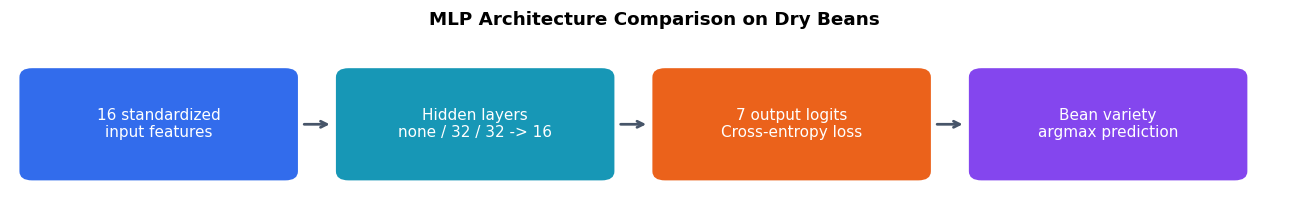

In [2]:
show_architecture(['16 standardized\ninput features', 'Hidden layers\nnone / 32 / 32 -> 16', '7 output logits\nCross-entropy loss', 'Bean variety\nargmax prediction'], 'MLP Architecture Comparison on Dry Beans')

## Imports and reproducibility

In [3]:
# Basic libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Dataset
from pathlib import Path

# Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# PyTorch
import torch
import torch.nn as nn
import torch.optim as optim

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
print("PyTorch:", torch.__version__)

PyTorch: 2.11.0+cpu


## Dataset summary

In [4]:
# Read the attached UCI Dry Bean dataset.
frame = pd.read_csv(next(Path('/kaggle/input').rglob('dry_bean.csv')))
X = frame.drop(columns=['Class'])
y = frame['Class']
print('Samples:', len(X), 'Features:', X.shape[1], 'Classes:', y.nunique())
print(y.value_counts())

Samples: 13611 Features: 16 Classes: 7
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


### Dataset class distribution

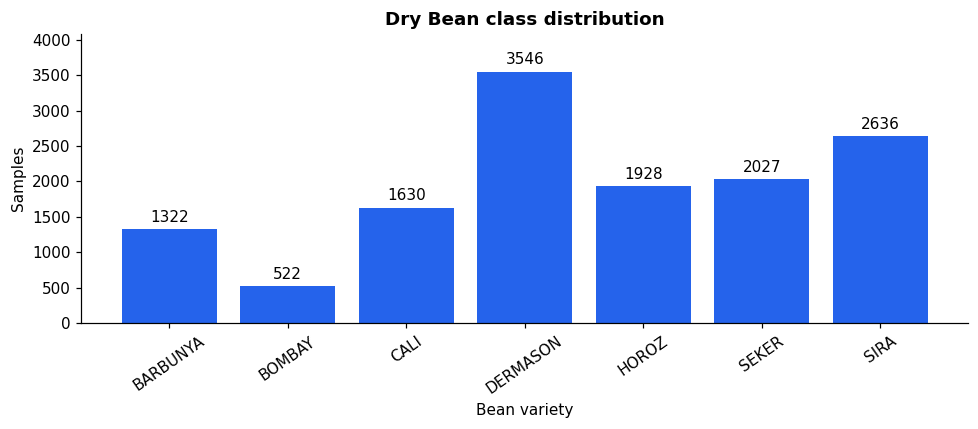

In [5]:
counts = y.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(counts.index, counts.values, color=PALETTE[0])
ax.bar_label(bars, padding=3)
ax.set(xlabel='Bean variety', ylabel='Samples', title='Dry Bean class distribution')
ax.tick_params(axis='x',rotation=35); ax.set_ylim(0, counts.max()*1.15)
plt.tight_layout(); plt.show()

The varieties are unevenly represented, so macro-averaged precision, recall, and F1 complement overall accuracy.

### Missing-value inspection

In [6]:
# Check missing values
print("Missing values in features:\n", X.isnull().sum())
print("\nMissing values in target:\n", y.isnull().sum())

Missing values in features:
 Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRatio        0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
Roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
dtype: int64

Missing values in target:
 0


### Label encoding

In [7]:
# Convert labels to numbers
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Encoded classes:", np.unique(y_encoded))
print("Label mapping:", dict(enumerate(label_encoder.classes_)))

Encoded classes: [0 1 2 3 4 5 6]
Label mapping: {0: 'BARBUNYA', 1: 'BOMBAY', 2: 'CALI', 3: 'DERMASON', 4: 'HOROZ', 5: 'SEKER', 6: 'SIRA'}


## Train/test split and standardization

In [8]:
# Split before fitting any feature preprocessing to avoid test-data leakage.
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=SEED, stratify=y_encoded
)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

In [9]:
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 10888
Testing samples: 2723


### Tensor conversion

In [10]:
# Convert to tensors
# Floating-point features and integer class indices match CrossEntropyLoss.
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
X_test_tensor  = torch.tensor(X_test, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train, dtype=torch.long)
y_test_tensor  = torch.tensor(y_test, dtype=torch.long)

## Configurable MLP

In [11]:
class MLP(nn.Module):
    def __init__(self, input_size, hidden_layers, output_size, activation=nn.ReLU):
        super(MLP, self).__init__()
        
        layers = []
        prev_size = input_size
        
        # Create hidden layers dynamically
        for h in hidden_layers:
            layers.append(nn.Linear(prev_size, h))
            layers.append(activation())
            prev_size = h
        
        # Output layer
        layers.append(nn.Linear(prev_size, output_size))
        
        # Combine all layers
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)

### Loss function

In [12]:
# Loss function
criterion = nn.CrossEntropyLoss()

### Training loop

In [13]:
def train_model(model, X_train, y_train, epochs=50, lr=0.001, batch_size=32):
    
    torch.manual_seed(SEED)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    
    dataset = torch.utils.data.TensorDataset(X_train, y_train)
    loader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True)
    
    losses = []
    
    for epoch in range(epochs):
        model.train()
        total_loss = 0
        
        for xb, yb in loader:
            optimizer.zero_grad()
            
            outputs = model(xb)
            loss = criterion(outputs, yb)
            
            loss.backward()
            optimizer.step()
            
            total_loss += loss.item() * len(yb)
        
        avg_loss = total_loss / len(dataset)
        losses.append(avg_loss)
        
        print(f"Epoch [{epoch+1}/{epochs}], Loss: {avg_loss:.4f}")
    
    return losses

### Evaluation metrics

In [14]:
def evaluate_model(model, X_test, y_test):
    """Compute class-balanced metrics using NumPy (sklearn is preprocessing-only)."""
    model.eval()
    with torch.no_grad():
        preds = model(X_test).argmax(dim=1).cpu().numpy()
    y_true = np.asarray(y_test)
    labels = np.arange(model(X_test[:1]).shape[1])
    cm = np.zeros((len(labels), len(labels)), dtype=int)
    np.add.at(cm, (y_true, preds), 1)
    tp = np.diag(cm).astype(float)
    predicted = cm.sum(axis=0)
    actual = cm.sum(axis=1)
    precision = np.divide(tp, predicted, out=np.zeros_like(tp), where=predicted != 0)
    recall = np.divide(tp, actual, out=np.zeros_like(tp), where=actual != 0)
    f1 = np.divide(2 * precision * recall, precision + recall,
                   out=np.zeros_like(tp), where=(precision + recall) != 0)
    return float(np.mean(y_true == preds)), precision.mean(), recall.mean(), f1.mean()

## Architecture comparison

In [15]:
input_size = X_train.shape[1]   # 16 features
output_size = len(np.unique(y_train))  # 7 classes

In [16]:
torch.manual_seed(SEED)
torch.set_num_threads(2)
# Model A
model_A = MLP(input_size, [], output_size)

print("\nTraining Model A...")
loss_A = train_model(model_A, X_train_tensor, y_train_tensor)


Training Model A...


Epoch [1/50], Loss: 1.2486


Epoch [2/50], Loss: 0.7320
Epoch [3/50], Loss: 0.5585


Epoch [4/50], Loss: 0.4649


Epoch [5/50], Loss: 0.4058


...

Epoch [46/50], Loss: 0.2158


Epoch [47/50], Loss: 0.2156


Epoch [48/50], Loss: 0.2154


Epoch [49/50], Loss: 0.2154


Epoch [50/50], Loss: 0.2152


In [17]:
torch.manual_seed(SEED)
torch.set_num_threads(2)
# Model B
model_B = MLP(input_size, [32], output_size)

print("\nTraining Model B...")
loss_B = train_model(model_B, X_train_tensor, y_train_tensor)


Training Model B...


Epoch [1/50], Loss: 0.8977


Epoch [2/50], Loss: 0.3177


Epoch [3/50], Loss: 0.2421


Epoch [4/50], Loss: 0.2233


...

Epoch [46/50], Loss: 0.1780


Epoch [47/50], Loss: 0.1775


Epoch [48/50], Loss: 0.1776


Epoch [49/50], Loss: 0.1771


Epoch [50/50], Loss: 0.1776


In [18]:
torch.manual_seed(SEED)
torch.set_num_threads(2)
# Model C
model_C = MLP(input_size, [32, 16], output_size)

print("\nTraining Model C...")
loss_C = train_model(model_C, X_train_tensor, y_train_tensor)


Training Model C...


Epoch [1/50], Loss: 0.8618


Epoch [2/50], Loss: 0.3029


Epoch [3/50], Loss: 0.2333


Epoch [4/50], Loss: 0.2165


...

Epoch [46/50], Loss: 0.1745


Epoch [47/50], Loss: 0.1741


Epoch [48/50], Loss: 0.1737


Epoch [49/50], Loss: 0.1737


Epoch [50/50], Loss: 0.1740


In [19]:
results = {}

for name, model in zip(
    ["A", "B", "C"],
    [model_A, model_B, model_C]
):
    acc, prec, rec, f1 = evaluate_model(model, X_test_tensor, y_test)
    
    results[name] = {
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1": f1
    }

# Display results
for k, v in results.items():
    print(f"\nModel {k}:")
    for metric, value in v.items():
        print(f"{metric}: {value:.4f}")


Model A:
Accuracy: 0.9199
Precision: 0.9341
Recall: 0.9308
F1: 0.9322

Model B:
Accuracy: 0.9232
Precision: 0.9364
Recall: 0.9316
F1: 0.9337

Model C:
Accuracy: 0.9218
Precision: 0.9354
Recall: 0.9317
F1: 0.9333


In [20]:
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

for name, model in zip(
    ["A", "B", "C"],
    [model_A, model_B, model_C]
):
    print(f"Model {name} Parameters:", count_params(model))

Model A Parameters: 119
Model B Parameters: 775
Model C Parameters: 1191


In [21]:
import pandas as pd

comparison = []

for name, model in zip(
    ["A", "B", "C"],
    [model_A, model_B, model_C]
):
    acc, prec, rec, f1 = evaluate_model(model, X_test_tensor, y_test)
    
    comparison.append([
        name,
        count_params(model),
        {"A": loss_A, "B": loss_B, "C": loss_C}[name][-1],
        acc,
        prec,
        rec,
        f1
    ])

df = pd.DataFrame(comparison, columns=[
    "Model", "Parameters", "Final Training Loss", "Accuracy", "Precision", "Recall", "F1-Score"
])


display(df.round(4))

,Model,Parameters,Final Training Loss,Accuracy,Precision,Recall,F1-Score
0,A,119,0.2152,0.9199,0.9341,0.9308,0.9322
1,B,775,0.1776,0.9232,0.9364,0.9316,0.9337
2,C,1191,0.1740,0.9218,0.9354,0.9317,0.9333


### Performance and model-size comparison

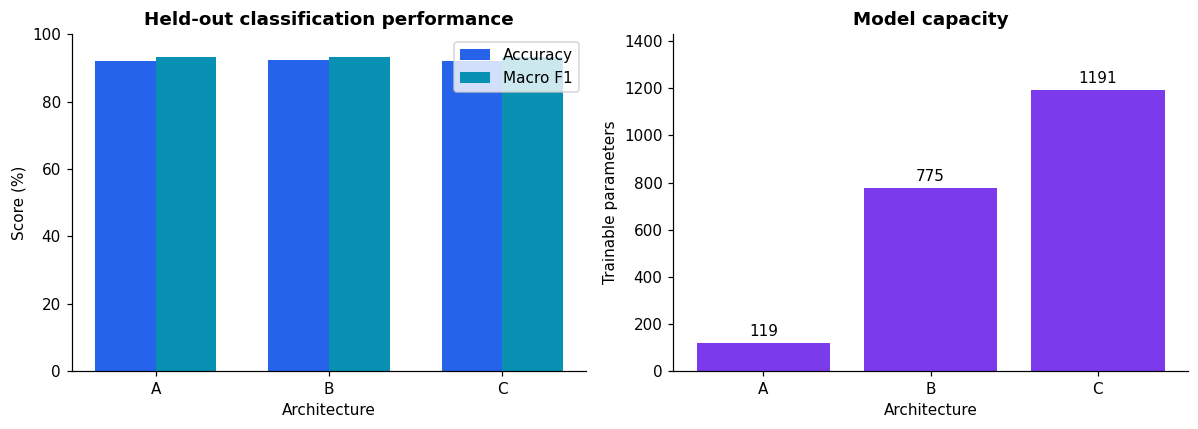

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
x = np.arange(len(df)); width=.35
axes[0].bar(x-width/2, df['Accuracy']*100, width, label='Accuracy',color=PALETTE[0])
axes[0].bar(x+width/2, df['F1-Score']*100, width, label='Macro F1',color=PALETTE[1])
axes[0].set_xticks(x,df['Model']); axes[0].set(xlabel='Architecture',ylabel='Score (%)',ylim=(0,100),title='Held-out classification performance'); axes[0].legend()
bars=axes[1].bar(df['Model'],df['Parameters'],color=PALETTE[3]); axes[1].bar_label(bars,padding=3)
axes[1].set(xlabel='Architecture',ylabel='Trainable parameters',title='Model capacity'); axes[1].set_ylim(0,df['Parameters'].max()*1.2)
plt.tight_layout(); plt.show()

### Training-loss curves

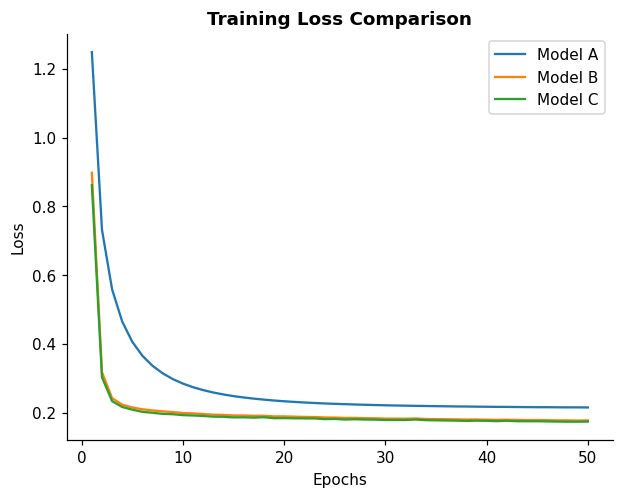

In [23]:
plt.figure()

plt.plot(range(1, len(loss_A) + 1), loss_A, label="Model A")
plt.plot(range(1, len(loss_B) + 1), loss_B, label="Model B")
plt.plot(range(1, len(loss_C) + 1), loss_C, label="Model C")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training Loss Comparison")

plt.legend()
plt.show()

## Best model and class confusions

In [24]:
best_model_name = max(results, key=lambda x: results[x]["Accuracy"])
print("Best Model:", best_model_name)

if best_model_name == "A":
    best_model = model_A
elif best_model_name == "B":
    best_model = model_B
else:
    best_model = model_C

Best Model: B


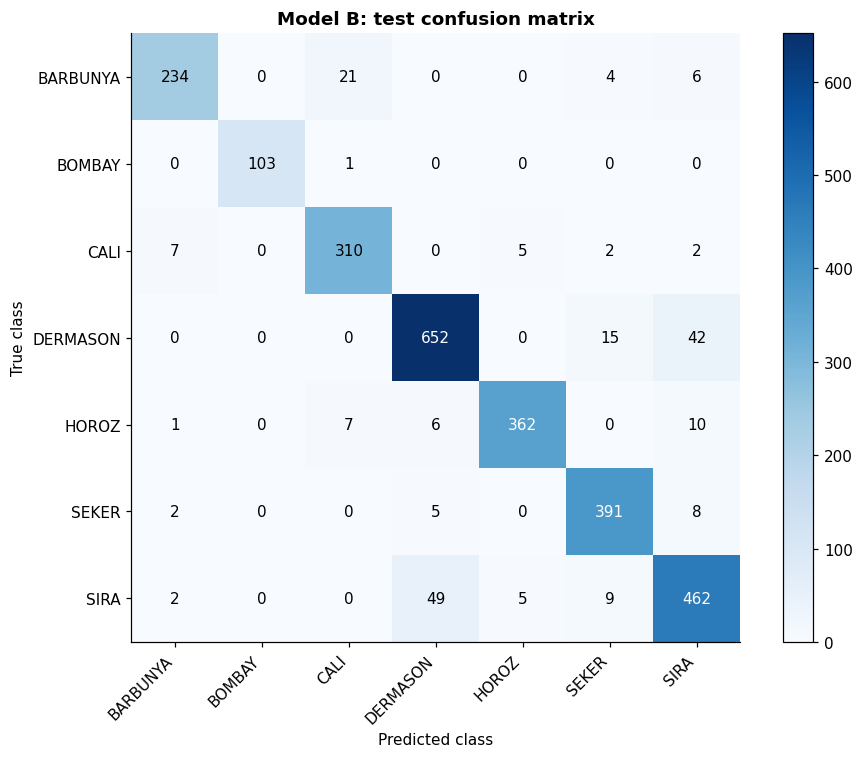

Most frequent directional confusion: SIRA -> DERMASON (49 examples)


In [25]:
best_model.eval()
with torch.no_grad():
    preds = best_model(X_test_tensor).argmax(dim=1).numpy()
cm = np.zeros((output_size, output_size), dtype=int)
np.add.at(cm, (y_test, preds), 1)
fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(cm, cmap="Blues")
fig.colorbar(image, ax=ax)
ax.set_xticks(range(output_size), label_encoder.classes_, rotation=45, ha="right")
ax.set_yticks(range(output_size), label_encoder.classes_)
ax.set(xlabel="Predicted class", ylabel="True class", title=f"Model {best_model_name}: test confusion matrix")
for i in range(output_size):
    for j in range(output_size):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout()
plt.show()
confusions = cm.copy()
np.fill_diagonal(confusions, 0)
i, j = np.unravel_index(confusions.argmax(), confusions.shape)
if confusions[i, j]:
    print(f"Most frequent directional confusion: {label_encoder.classes_[i]} -> "
          f"{label_encoder.classes_[j]} ({confusions[i, j]} examples)")
else:
    print("No test examples were misclassified.")

## Effect of training duration

In [26]:
epoch_results = {}

for epochs in [10, 25, 50]:
    torch.manual_seed(SEED)
    hidden_layers = {"A": [], "B": [32], "C": [32, 16]}[best_model_name]
    model = MLP(input_size, hidden_layers, output_size)
    
    print(f"\nTraining for {epochs} epochs")
    train_model(model, X_train_tensor, y_train_tensor, epochs=epochs)
    
    acc, prec, rec, f1 = evaluate_model(model, X_test_tensor, y_test)
    
    epoch_results[epochs] = (acc, prec, rec, f1)

# Display results
for e, metrics in epoch_results.items():
    print(f"\nEpochs: {e}")
    print(f"Accuracy: {metrics[0]:.4f}, F1: {metrics[3]:.4f}")


Training for 10 epochs


Epoch [1/10], Loss: 0.8977


Epoch [2/10], Loss: 0.3177


Epoch [3/10], Loss: 0.2421


Epoch [4/10], Loss: 0.2233


...

Epoch [46/50], Loss: 0.1780


Epoch [47/50], Loss: 0.1775


Epoch [48/50], Loss: 0.1776


Epoch [49/50], Loss: 0.1771


Epoch [50/50], Loss: 0.1776

Epochs: 10
Accuracy: 0.9229, F1: 0.9344

Epochs: 25
Accuracy: 0.9266, F1: 0.9374

Epochs: 50
Accuracy: 0.9232, F1: 0.9337


## Discussion

1. **Highest accuracy:** use the comparison table and `best_model_name`. The winning architecture is computed from this run, rather than assumed to be Model C.
2. **Fewest parameters:** Model A has `16 × 7 + 7 = 119` parameters. Model B has 775 and Model C has 1,191. Biases are included.
3. **Role of hidden layers:** ReLU hidden layers permit nonlinear decision regions, whereas Model A is a linear classifier in standardized feature space. Compare the measured loss and accuracy to assess whether that additional capacity helped.
4. **Depth and performance:** adding a layer increases capacity but does not guarantee improvement. Optimization, overfitting, and class overlap can limit the benefit.
5. **Accuracy versus cost:** compare accuracy and macro F1 with the parameter counts. Parameter count is a model-size proxy; execution time is a separate quantity. A smaller model with similar measured performance may be preferable.

The assignment selects an architecture using testing accuracy and repeats epoch comparisons on that test set. These are exploratory results: repeated test inspection influences model selection, so the reported maximum is not an independent estimate of a final tuned model. For a separate deployment study, select architectures and epochs on a validation split and evaluate the test set once.

### Retained run

With seed 42, Model B achieved the highest baseline test accuracy (92.32%), compared with 91.99% for Model A and 92.18% for Model C. Model B also had the highest baseline macro F1 (0.9337). This run therefore favors the one-hidden-layer model for accuracy and model size among the nonlinear alternatives. The duration study for Model B reached 92.29%, 92.66%, and 92.32% at 10, 25, and 50 epochs, respectively: extra training did not monotonically improve testing accuracy. These are observations of the saved run, not guarantees for every execution.